In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib
from matplotlib import cm
import torch
import os

import sys
sys.path.insert(0, '../testproblems/steadydiffusion')
from manufacturedsolutions import *
sys.path.insert(0, '../ml')
from modelloader import loadmodelfromlabel
from NeuralOperator import NeuralOperator
from customlosses import *
from quadrature import *
from customlayers import discretize_functions
from basisfunctions import *

In [2]:
%load_ext autoreload
%autoreload 2

In [33]:
from NeuralOperator import NeuralOperator

logdir = '../../../nnlogs'
device = 'cuda:0'

sublogdir = 'steadydiffusion_modelNGOs'

projection = loadmodelfromlabel(model=NeuralOperator, label='modelNGO', logdir=logdir, sublogdir=sublogdir, device=device)
projection.hparams['modeltype'] = 'projection'
projection.hparams['dtype'] = torch.float64
projection.hparams['gamma_stabilization'] = 100
projection.__init__(projection.hparams)

FEM = loadmodelfromlabel(model=NeuralOperator, label='modelNGO', logdir=logdir, sublogdir=sublogdir, device=device)
FEM.hparams['modeltype'] = 'FEM'
FEM.hparams['dtype'] = torch.float64
FEM.hparams['Neumannseries'] = True
FEM.hparams['Neumannseries_order'] = 1
FEM.hparams['project_materialparameters'] = True
FEM.hparams['gamma_stabilization'] = 100
FEM.__init__(FEM.hparams)

modelNGO = loadmodelfromlabel(model=NeuralOperator, label='modelNGO', logdir=logdir, sublogdir=sublogdir, device=device)
modelNGO_Neumann = loadmodelfromlabel(model=NeuralOperator, label='modelNGO_Neumann', logdir=logdir, sublogdir=sublogdir, device=device)
modelNGO_SI = loadmodelfromlabel(model=NeuralOperator, label='modelNGO_SI', logdir=logdir, sublogdir=sublogdir, device=device)



modeldict = {#'Projection': projection,
             'Neumann FEM': FEM,
             'Model NGO': modelNGO,
            'Neumann model NGO': modelNGO_Neumann,
            # 'Scale equivariant model NGO': modelNGO_SI,
}

0.0
(10,)
(10,)
(10,)
0.1
(10,)
(10,)
(10,)
0.2
(10,)
(10,)
(10,)
0.3
(10,)
(10,)
(10,)
0.4
(10,)
(10,)
(10,)
0.5
(10,)
(10,)
(10,)
0.6
(10,)
(10,)
(10,)
0.7
(10,)
(10,)
(10,)
0.8
(10,)
(10,)
(10,)
0.9
(10,)
(10,)
(10,)
1.0
(10,)
(10,)
(10,)


/tmp/ipykernel_4085391/847891483.py:98: UserWarning: linestyle is redundantly defined by the 'linestyle' keyword argument and the fmt string ".-" (-> linestyle='-'). The keyword argument will take precedence.
  plots.append(ax.errorbar(c_thetas, L2_scaled_avg[m], yerr=yerr[m], fmt=".-", capsize=6, ms=15, label=str(model), color=colors[m], linestyle=linestyles[m]))


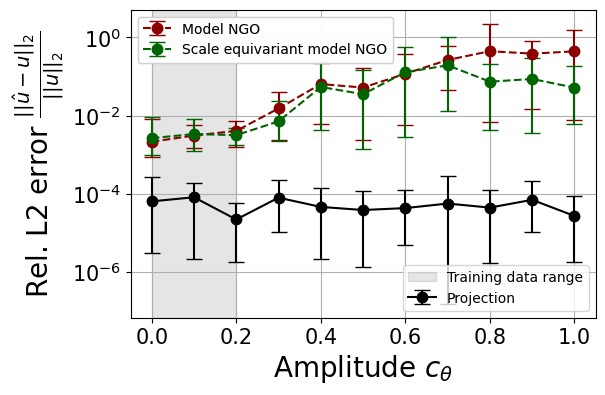

In [ ]:
N_samples = 30
N_samples_min = 10
lb = 0.02

alpha = 0.05
q_low = alpha/2
q_high = 1 - q_low


c_thetas = np.array([0,0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9,1])

# l = np.array([1])

# l = np.array([0.4, 0.3, 0.2, 0.1, 0.05])
L2_scaled_avg = np.zeros((len(modeldict),len(c_thetas)))
yerr = np.zeros((len(modeldict),2,len(c_thetas)))
spectralradii_avg = np.zeros(len(c_thetas))
yerr_radii = np.zeros((2,len(c_thetas)))

size_title = 20
size_ticklabels = 15
size_axeslabels = 20

# quadrature = GaussLegendreQuadrature2D(n_elements=1, Q=100)
quadrature = UniformQuadrature2D(Q=100)
x = quadrature.xi_Omega
w = quadrature.w_Omega

linestyles=['-','--','--','--','--','--', '--','--','--','--','--','--']
colors = ['black','darkred','darkgreen']
# markers = ['o','^','o','^','o','^','o']
    
for i in range(len(c_thetas)):
    print(c_thetas[i])
    dataset = ManufacturedSolutionsSetDarcy_ctheta(N_samples=N_samples, variables=['x','x'], l_min=[0.5,0.5], l_max=[1,1], c_theta_min=c_thetas[i], c_theta_max=c_thetas[i])
    theta = dataset.theta
    f = dataset.f
    etat = dataset.etat
    etab = dataset.etab
    gl = dataset.gl
    gr = dataset.gr
    u = dataset.u
    m=0
    for model in modeldict:
        u_exact = discretize_functions(u, x)
        u_hat = modeldict[str(model)].simforward(theta, f, etab, etat, gl, gr, x, u)
        theta_d = discretize_functions(theta, modeldict[str(model)].xi_Omega)
        theta_min = np.amin(theta_d, axis=-1)
        # if modeldict[str(model)].hparams['Neumannseries']==True:
            # spectralradii = modeldict[str(model)].Neumann_criterion(theta).detach().cpu().numpy()
            # spectralradii = spectralradii[theta_min>lb]
            # spectralradii_avg[i] = np.average(spectralradii, axis=-1)
        # q_l_radii = np.quantile(spectralradii, q_low)
        # q_h_radii = np.quantile(spectralradii, q_high)
        # yerr_radii[:,i] = np.array([spectralradii_avg[i] - q_l_radii, -spectralradii_avg[i] + q_h_radii])
        L22_diff = np.sum(w[None,:]*(u_hat - u_exact)**2, axis=-1)
        L2_diff = L22_diff**(1/2)
        L22_norm = np.sum(w[None,:]*(u_exact)**2, axis=-1)
        L2_norm = L22_norm**(1/2)
        L2_scaled_array = L2_diff/np.maximum(L2_norm, 1e-7*np.ones_like(L2_norm))
        L2_scaled_array = L2_scaled_array[theta_min>lb]
        if len(L2_scaled_array)<N_samples_min:
            print("Not enough samples for c_theta =", c_thetas[i], "and model", model)
            break
        L2_scaled_array = L2_scaled_array[:N_samples_min]
        print(L2_scaled_array.shape)
        L2_scaled_avg[m,i] = np.average(L2_scaled_array)
        q_l = np.quantile(L2_scaled_array, q_low)
        q_h = np.quantile(L2_scaled_array, q_high)
        yerr[m,:,i] = np.array([L2_scaled_avg[m,i] - q_l, -L2_scaled_avg[m,i] + q_h])
        m+=1

    
# L2_scaled_avg[L2_scaled_avg<0] = np.nan
# yerr[yerr<0] = np.nan
        
fig, ax = plt.subplots(1,1, figsize=(6, 4))
fig.subplots_adjust(left=None, bottom=None, right=None, top=None, wspace=0.4, hspace=0.4)

plots = []
plots.append(ax.axvspan(0,0.2, color='black', alpha=0.1, label='Training data range'))
# plots.append(ax.errorbar(c_thetas, spectralradii_avg, yerr=yerr_radii, fmt=".-", capsize=6, ms=15, label='Spectral radius', color='red', linestyle='-'))
m=0
ax.tick_params(axis='both', labelsize=size_ticklabels)
ax.set_xlabel(r'Amplitude $c_\theta$', fontsize=size_axeslabels)
ax.set_ylabel(r'Rel. L2 error $\frac{||\hat{u}-u||_2}{||u||_2}$', fontsize=size_axeslabels)
ax.set_yscale('log')
# ax.set_xlim(1e-1, 1e1)
# ax.set_ylim(1e-6, 1e6)
# ax.set_yticks([1e-6, 1e-4, 1e-2, 1e0, 1e2, 1e4])
# ax.set_yticks([1e-4, 1e-3, 1e-2, 1e-1, 1e0, 1e1])
# ax.set_xscale('log')
ax.grid()
# ax.set_title(sublogdir, fontsize=size_title)
for model in modeldict:
    # ax.plot(l, L2_scaled_avg[m], color=colors[m], label=str(model), linestyle=linestyles[m], marker='o')
    # plots.append(ax.plot(c_thetas, L2_scaled_avg[m], label=str(model), color=colors[m], linestyle=linestyles[m], marker='o')[0])
    plots.append(ax.errorbar(c_thetas, L2_scaled_avg[m], yerr=yerr[m], fmt=".-", capsize=6, ms=15, label=str(model), color=colors[m], linestyle=linestyles[m]))
        # plt.savefig(str(m)+".svg", bbox_inches='tight')#, transparent=True)
    m+=1
    # plt.legend(fontsize=10, loc='upper right')
    # plt.savefig(str(m)+".svg", bbox_inches='tight')#, transparent=True)
plt.legend(fontsize=10, ncols=1)
plt.legend(fontsize=8, loc='lower right', ncols=1)
legend1 = ax.legend(handles=plots[0:2], fontsize=10, ncols=1, loc='lower left')
plt.gca().add_artist(legend1)
legend2 = ax.legend(handles=plots[2:], fontsize=10, ncols=1, loc='upper left')
plt.gca().add_artist(legend2)
plt.savefig("ctheta.svg", bbox_inches='tight')#, transparent=True)

plt.show()

0.1
(2,)
(2,)
(2,)
0.2
(2,)
(2,)
(2,)
0.4
(2,)
(2,)
(2,)
0.6
(2,)
(2,)
(2,)
0.8
(2,)
(2,)
(2,)
1.0
(2,)
(2,)
(2,)
1.2
(2,)
(2,)
(2,)
1.4
(2,)
(2,)
(2,)
1.6
(2,)
(2,)
(2,)
1.8
(2,)
(2,)
(2,)
2.0
(2,)
(2,)
(2,)


/tmp/ipykernel_4085391/4248126501.py:99: UserWarning: linestyle is redundantly defined by the 'linestyle' keyword argument and the fmt string ".-" (-> linestyle='-'). The keyword argument will take precedence.
  plots.append(ax.errorbar(b_thetas, L2_scaled_avg[m], yerr=yerr[m], fmt=".-", capsize=6, ms=15, label=str(model), color=colors[m], linestyle=linestyles[m]))


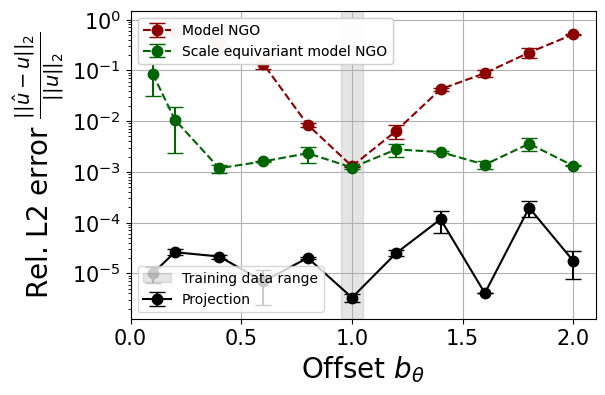

In [22]:
N_samples = 10
N_samples_min = 2
lb = 0.02

alpha = 0.05
q_low = alpha/2
q_high = 1 - q_low

b_thetas = np.array([0.1,0.2,0.4,0.6,0.8,1,1.2,1.4,1.6,1.8,2])

# l = np.array([1])

# l = np.array([0.4, 0.3, 0.2, 0.1, 0.05])
L2_scaled_avg = np.zeros((len(modeldict),len(c_thetas)))
yerr = np.zeros((len(modeldict),2,len(c_thetas)))
spectralradii_avg = np.zeros(len(c_thetas))
yerr_radii = np.zeros((2,len(c_thetas)))

size_title = 20
size_ticklabels = 15
size_axeslabels = 20

# quadrature = GaussLegendreQuadrature2D(n_elements=1, Q=100)
quadrature = UniformQuadrature2D(Q=100)
x = quadrature.xi_Omega
w = quadrature.w_Omega

linestyles=['-','--','--','--','--','--', '--','--','--','--','--','--']
colors = ['black','darkred','darkgreen']
# markers = ['o','^','o','^','o','^','o']
    
for i in range(len(c_thetas)):
    print(b_thetas[i])
    dataset = ManufacturedSolutionsSetDarcy_btheta(N_samples=N_samples, variables=['x','x'], l_min=[0.5,0.5], l_max=[1,1], b_theta_min=b_thetas[i], b_theta_max=b_thetas[i])
    theta = dataset.theta
    f = dataset.f
    etat = dataset.etat
    etab = dataset.etab
    gl = dataset.gl
    gr = dataset.gr
    u = dataset.u
    m=0
    for model in modeldict:
        u_exact = discretize_functions(u, x)
        u_hat = modeldict[str(model)].simforward(theta, f, etab, etat, gl, gr, x, u)
        theta_d = discretize_functions(theta, modeldict[str(model)].xi_Omega)
        theta_min = np.amin(theta_d, axis=-1)
        # if modeldict[str(model)].hparams['Neumannseries']==True:
            # spectralradii = modeldict[str(model)].Neumann_criterion(theta).detach().cpu().numpy()
            # spectralradii = spectralradii[theta_min>lb]
            # spectralradii_avg[i] = np.average(spectralradii, axis=-1)
        # q_l_radii = np.quantile(spectralradii, q_low)
        # q_h_radii = np.quantile(spectralradii, q_high)
        # yerr_radii[:,i] = np.array([spectralradii_avg[i] - q_l_radii, -spectralradii_avg[i] + q_h_radii])
        L22_diff = np.sum(w[None,:]*(u_hat - u_exact)**2, axis=-1)
        L2_diff = L22_diff**(1/2)
        L22_norm = np.sum(w[None,:]*(u_exact)**2, axis=-1)
        L2_norm = L22_norm**(1/2)
        L2_scaled_array = L2_diff/np.maximum(L2_norm, 1e-7*np.ones_like(L2_norm))
        L2_scaled_array = L2_scaled_array[theta_min>lb]
        if len(L2_scaled_array)<N_samples_min:
            print("Not enough samples for c_theta =", b_thetas[i], "and model", model)
            break
        L2_scaled_array = L2_scaled_array[:N_samples_min]
        print(L2_scaled_array.shape)
        L2_scaled_avg[m,i] = np.average(L2_scaled_array)
        q_l = np.quantile(L2_scaled_array, q_low)
        q_h = np.quantile(L2_scaled_array, q_high)
        yerr[m,:,i] = np.array([L2_scaled_avg[m,i] - q_l, -L2_scaled_avg[m,i] + q_h])
        m+=1

    
# L2_scaled_avg[L2_scaled_avg<0] = np.nan
# yerr[yerr<0] = np.nan
        
fig, ax = plt.subplots(1,1, figsize=(6, 4))
fig.subplots_adjust(left=None, bottom=None, right=None, top=None, wspace=0.4, hspace=0.4)

plots = []
plots.append(ax.axvspan(0.95,1.05, color='black', alpha=0.1, label='Training data range'))
# plots.append(ax.errorbar(c_thetas, spectralradii_avg, yerr=yerr_radii, fmt=".-", capsize=6, ms=15, label='Spectral radius', color='red', linestyle='-'))
m=0
ax.tick_params(axis='both', labelsize=size_ticklabels)
ax.set_xlabel(r'Offset $b_\theta$', fontsize=size_axeslabels)
ax.set_ylabel(r'Rel. L2 error $\frac{||\hat{u}-u||_2}{||u||_2}$', fontsize=size_axeslabels)
ax.set_yscale('log')
# ax.set_xlim(1e-1, 1e1)
# ax.set_ylim(1e-6, 1e6)
# ax.set_yticks([1e-6, 1e-4, 1e-2, 1e0, 1e2, 1e4])
# ax.set_yticks([1e-4, 1e-3, 1e-2, 1e-1, 1e0, 1e1])
ax.set_xticks([0,0.5,1,1.5,2])
ax.set_xlim(0,2.1)
# ax.set_xscale('log')
ax.grid()
# ax.set_title(sublogdir, fontsize=size_title)
for model in modeldict:
    # ax.plot(l, L2_scaled_avg[m], color=colors[m], label=str(model), linestyle=linestyles[m], marker='o')
    # plots.append(ax.plot(c_thetas, L2_scaled_avg[m], label=str(model), color=colors[m], linestyle=linestyles[m], marker='o')[0])
    plots.append(ax.errorbar(b_thetas, L2_scaled_avg[m], yerr=yerr[m], fmt=".-", capsize=6, ms=15, label=str(model), color=colors[m], linestyle=linestyles[m]))
        # plt.savefig(str(m)+".svg", bbox_inches='tight')#, transparent=True)
    m+=1
    # plt.legend(fontsize=10, loc='upper right')
    # plt.savefig(str(m)+".svg", bbox_inches='tight')#, transparent=True)
plt.legend(fontsize=10, ncols=1)
plt.legend(fontsize=8, loc='lower right', ncols=1)
legend1 = ax.legend(handles=plots[0:2], fontsize=10, ncols=1, loc='lower left')
plt.gca().add_artist(legend1)
legend2 = ax.legend(handles=plots[2:], fontsize=10, ncols=1, loc='upper left')
plt.gca().add_artist(legend2)
plt.savefig("btheta.svg", bbox_inches='tight')#, transparent=True)

plt.show()

IndexError: boolean index did not match indexed array along dimension 0; dimension is 3 but corresponding boolean dimension is 20

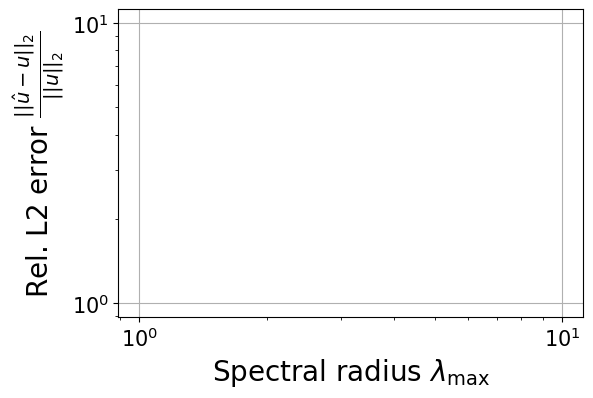

In [ ]:
N_samples = 20
N_samples_min = 10
lb = 0.02

alpha = 0.05
q_low = alpha/2
q_high = 1 - q_low


# c_thetas = np.array([0,0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9,1])

# l = np.array([1])

# l = np.array([0.4, 0.3, 0.2, 0.1, 0.05])
L2_scaled_array = np.zeros((len(modeldict),N_samples))

size_title = 20
size_ticklabels = 15
size_axeslabels = 20

# quadrature = GaussLegendreQuadrature2D(n_elements=1, Q=100)
quadrature = UniformQuadrature2D(Q=100)
x = quadrature.xi_Omega
w = quadrature.w_Omega

linestyles=['-','-','--','--','--','--', '--','--','--','--','--','--']
colors = ['grey','darkred','darkgreen']
# markers = ['o','^','o','^','o','^','o']
    
dataset = ManufacturedSolutionsSetDarcy_ctheta(N_samples=N_samples, variables=['x','x'], l_min=[0.5,0.5], l_max=[1,1], c_theta_min=0, c_theta_max=1)
theta = dataset.theta
f = dataset.f
etat = dataset.etat
etab = dataset.etab
gl = dataset.gl
gr = dataset.gr
u = dataset.u
m=0
# model = loadmodelfromlabel(model=NeuralOperator, label='modelNGO_Neumann_noSE', logdir=logdir, sublogdir=sublogdir, device=device)
# spectralradii = model.Neumann_criterion(theta).detach().cpu().numpy()
# spectralradii_avg[i] = np.median(spectralradii, axis=-1)
# q_l_radii = np.quantile(spectralradii, q_low)
# q_h_radii = np.quantile(spectralradii, q_high)

spectralradii = FEM.Neumann_criterion(theta).detach().cpu().numpy()

for model in modeldict:
    u_exact = discretize_functions(u, x)
    u_hat = modeldict[str(model)].simforward(theta, f, etab, etat, gl, gr, x, u)
    theta_d = discretize_functions(theta, modeldict[str(model)].xi_Omega)
    theta_min = np.amin(theta_d, axis=-1)
    L22_diff = np.sum(w[None,:]*(u_hat - u_exact)**2, axis=-1)
    L2_diff = L22_diff**(1/2)
    L22_norm = np.sum(w[None,:]*(u_exact)**2, axis=-1)
    L2_norm = L22_norm**(1/2)
    L2_scaled_array[m] = L2_diff/np.maximum(L2_norm, 1e-7*np.ones_like(L2_norm))
    
    # L2_scaled_avg[m,i] = np.median(L2_scaled_array)
    # q_l = np.quantile(L2_scaled_array, q_low)
    # q_h = np.quantile(L2_scaled_array, q_high)
    # yerr[m,:,i] = np.array([L2_scaled_avg[m,i] - q_l, -L2_scaled_avg[m,i] + q_h])
    m+=1

    
# L2_scaled_avg[L2_scaled_avg<0] = np.nan
# yerr[yerr<0] = np.nan
        
fig, ax = plt.subplots(1,1, figsize=(6, 4))
fig.subplots_adjust(left=None, bottom=None, right=None, top=None, wspace=0.4, hspace=0.4)

plots = []
# plots.append(ax.axvspan(0,0.2, color='black', alpha=0.1, label='Training data range'))
# plots.append(ax.errorbar(c_thetas, spectralradii_avg, yerr=yerr_radii, fmt=".-", capsize=6, ms=15, label='Spectral radius', color='red', linestyle='-'))
m=0
ax.tick_params(axis='both', labelsize=size_ticklabels)
ax.set_xlabel(r'Spectral radius $\lambda_\mathrm{max}}$', fontsize=size_axeslabels)
ax.set_ylabel(r'Rel. L2 error $\frac{||\hat{u}-u||_2}{||u||_2}$', fontsize=size_axeslabels)
ax.set_yscale('log')
# ax.set_xlim(1e-3, 1e1)
# ax.set_ylim(1e-6, 1e6)
# ax.set_xticks([1e-6, 1e-4, 1e-2, 1e0, 1e2, 1e4])
# ax.set_xticks([1e-4, 1e-3, 1e-2, 1e-1, 1e0, 1e1, 1e2, 1e3])
ax.set_xscale('log')
ax.grid()
# ax.set_title(sublogdir, fontsize=size_title)
spectralradii = spectralradii[theta_min>lb]
L2_scaled_array = L2_scaled_array[:,theta_min>lb]
if L2_scaled_array.shape[1] < N_samples_min:
    print("Not enough samples for spectral radius and model")
    print("Shape of L2_scaled_array:", L2_scaled_array.shape)
    print("Shape of spectralradii:", spectralradii.shape)
    exit()
else:
    spectralradii = spectralradii[:N_samples_min]
    L2_scaled_array = L2_scaled_array[:N_samples_min]
    print("Shape of L2_scaled_array:", L2_scaled_array.shape)
    print("Shape of spectralradii:", spectralradii.shape)
for model in modeldict:
    # ax.plot(l, L2_scaled_avg[m], color=colors[m], label=str(model), linestyle=linestyles[m], marker='o')
    # plots.append(ax.plot(c_thetas, L2_scaled_avg[m], label=str(model), color=colors[m], linestyle=linestyles[m], marker='o')[0])
    plots.append(ax.scatter(spectralradii, L2_scaled_array[m], color=colors[m], label=str(model), alpha=0.5))#,c=theta_bar[theta_bar>lb]))
    # plots.append(ax.errorbar(c_thetas, L2_scaled_avg[m], yerr=yerr[m], fmt=".-", capsize=6, ms=15, label=str(model), color=colors[m], linestyle=linestyles[m]))
        # plt.savefig(str(m)+".svg", bbox_inches='tight')#, transparent=True)
    m+=1
    # plt.legend(fontsize=10, loc='upper right')
    # plt.savefig(str(m)+".svg", bbox_inches='tight')#, transparent=True)
plt.legend(fontsize=10, ncols=1)
# plt.legend(fontsize=8, loc='upper left', ncols=1)
# legend1 = ax.legend(handles=plots[0:2], fontsize=10, ncols=1, loc='lower right')
# plt.gca().add_artist(legend1)
# legend2 = ax.legend(handles=plots[2:7], fontsize=10, ncols=1, loc='upper left')
# plt.gca().add_artist(legend2)
# plt.colorbar(plots[0])
plt.savefig("errorvsspectralradius.svg", bbox_inches='tight')#, transparent=True)

plt.show()
